# Country Mentions in UN Briefings - Complete Analysis

## Overview
This notebook performs end-to-end analysis of country mentions in UN Noon Briefing documents:
1. Load and clean country data from Wikipedia
2. Extract sections from the database
3. Count country mentions using regex pattern matching
4. Generate interactive visualizations
5. Analyze temporal trends and country-specific patterns

## Issue #47
Build a country mentions heatmap from UN Noon Briefing database with proper false-positive handling.

## Imports

In [1]:
import re
from pathlib import Path
from typing import Dict

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import curl_cffi
from bs4 import BeautifulSoup
from loguru import logger
from bokeh.plotting import figure, output_file, save
from bokeh.models import HoverTool, ColumnDataSource, ColorBar, LinearColorMapper
from bokeh.palettes import Viridis256
from bokeh.transform import transform

from un_llm_analysis.database import get_db_connection
from un_llm_analysis.config import COUNTRY_CSV_PATH, PROCESSED_DATA_DIR

%matplotlib inline

## Configuration

In [2]:
# Dev database location
DB_PATH = PROCESSED_DATA_DIR / "database" / "briefings.db"
OUTPUT_DIR = PROCESSED_DATA_DIR / "output"

# Create output directory if needed
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

logger.info(f"Database: {DB_PATH}")
logger.info(f"Database exists: {DB_PATH.exists()}")
logger.info(f"Output directory: {OUTPUT_DIR}")

2026-10-04 10:09:06.957 | INFO     | __main__:<module>:8 - Database: C:\Users\danie\PycharmProjects\correlaid-mentoring-project\data\processed\database\briefings.db
2026-10-04 10:09:06.958 | INFO     | __main__:<module>:9 - Database exists: True
2026-10-04 10:09:06.959 | INFO     | __main__:<module>:10 - Output directory: C:\Users\danie\PycharmProjects\correlaid-mentoring-project\data\processed\output


## Function Definitions

In [3]:
def get_countries_from_wikipedia() -> pd.DataFrame:
    """Scrape country data from Wikipedia."""
    url = "https://en.wikipedia.org/wiki/List_of_alternative_country_names"
    response = curl_cffi.get(url, impersonate="chrome")
    soup = BeautifulSoup(response.text, "html.parser")
    tables = soup.find_all(class_="wikitable")

    data = []
    for table in tables:
        for row in table.find_all("tr")[1:]:  # Skip header row
            cell_data = row.find_all("td")
            if len(cell_data) == 3:
                code, name, names = cell_data
                country_name = name.find("a")["title"].strip()
                other_names = "|".join(
                    [x.text.strip() for x in names.find_all("b")]
                    + [x.text.strip() for x in names.find_all("i")]
                )
                data.append((code.text.strip(), country_name, other_names))

    return pd.DataFrame(data, columns=["code", "name", "alternative_names"])


def get_countries_data(csv_path: Path | str) -> pd.DataFrame:
    """Load country data from CSV reference file."""
    return pd.read_csv(csv_path)

In [4]:
def get_sections_from_db(db_path: Path | str) -> pd.DataFrame:
    """Extract briefing sections from SQLite database."""
    conn = get_db_connection(str(db_path))
    
    try:
        query = """
        SELECT
            s.section_id,
            s.briefing_id,
            s.text,
            b.briefing_date
        FROM section s
        JOIN briefing b ON s.briefing_id = b.briefing_id
        WHERE s.text IS NOT NULL AND b.briefing_date IS NOT NULL
        """
        
        sections_df = pd.read_sql_query(query, conn)
    finally:
        conn.close()

    # Parse date and extract month
    sections_df['briefing_date'] = pd.to_datetime(sections_df['briefing_date'])
    sections_df['month'] = sections_df['briefing_date'].dt.to_period('M')

    return sections_df[['section_id', 'text', 'month']]

In [5]:
def clean_alternative_names(alt_names_str: str) -> str:
    """Remove problematic abbreviations from alternative names."""
    if pd.isna(alt_names_str):
        return ""
    
    alt_names = alt_names_str.split("|")
    problematic = {'png', 'and', 'or', 'usa'}
    alt_names = [
        name for name in alt_names 
        if name.strip().lower() not in problematic
    ]
    
    return "|".join(alt_names)


def build_search_dict(country_df: pd.DataFrame) -> Dict[str, str]:
    """Build mapping of search terms to country codes.
    
    Only matches country NAMES, not codes, to prevent false positives.
    """
    search_dict = {}

    for _, row in country_df.iterrows():
        code = row['code'].strip() if pd.notna(row['code']) else ""
        name = row['name'].strip() if pd.notna(row['name']) else ""
        alt_names = row['alternative_names'].split("|") if pd.notna(row['alternative_names']) else []

        country_key = code if code else name

        # Only match full country names - NOT codes
        if name:
            search_dict[name.lower()] = country_key
        
        # Only include alternatives with alphanumeric content
        for alt in alt_names:
            alt = alt.strip().lower()
            if alt and any(c.isalnum() for c in alt):
                search_dict[alt] = country_key

    return search_dict


def compile_search_pattern(search_dict: Dict[str, str]) -> re.Pattern:
    """Compile word-boundary-aware regex pattern for matching."""
    pattern = r'\b(' + '|'.join(re.escape(term) for term in search_dict.keys()) + r')\b'
    return re.compile(pattern, re.IGNORECASE)

In [6]:
def count_mentions_in_section(
    section_text: str,
    search_dict: Dict[str, str],
    compiled_regex: re.Pattern
) -> Dict[str, int]:
    """Count country mentions in a single section of text."""
    counts = {}

    for match in compiled_regex.finditer(section_text):
        matched_term = match.group(1).lower()
        country_key = search_dict[matched_term]
        counts[country_key] = counts.get(country_key, 0) + 1

    return counts


def process_sections_to_heatmap(
    sections_df: pd.DataFrame,
    country_df: pd.DataFrame
) -> pd.DataFrame:
    """Process all sections and generate heatmap data."""
    search_dict = build_search_dict(country_df)
    compiled_regex = compile_search_pattern(search_dict)

    all_country_counts = {}

    for _, row in sections_df.iterrows():
        section_text = row['text']
        section_month = row['month']

        # Count mentions for this section
        counts = count_mentions_in_section(section_text, search_dict, compiled_regex)

        # Aggregate by (month, country) key
        for country_code, count in counts.items():
            key = (section_month, country_code)
            all_country_counts[key] = all_country_counts.get(key, 0) + count

    # Convert to DataFrame format
    heatmap_data = [
        {
            'month': str(month),
            'country_code': code,
            'count': count
        }
        for (month, code), count in all_country_counts.items()
    ]

    return pd.DataFrame(heatmap_data)

In [7]:
def create_bokeh_heatmap(
    heatmap_df: pd.DataFrame,
    output_path: str = 'heatmap.html',
    top_n: int = 25
) -> None:
    """Create interactive Bokeh heatmap visualization."""
    # Filter to top N countries
    top_countries = heatmap_df.groupby('country_code')['count'].sum().nlargest(top_n).index
    heatmap_df = heatmap_df[heatmap_df['country_code'].isin(top_countries)].copy()
    heatmap_df = heatmap_df.sort_values(['month', 'country_code'])

    # Apply log scale for better color distribution
    heatmap_df['count_log'] = np.log1p(heatmap_df['count'])
    max_count_log = heatmap_df['count_log'].max()

    # Set up color mapping
    color_mapper = LinearColorMapper(
        palette=Viridis256,
        low=0,
        high=max_count_log
    )
    source = ColumnDataSource(heatmap_df)

    # Create figure
    p = figure(
        title=f"Country Mentions Heatmap - Top {top_n} Countries (log scale)",
        x_axis_label='Month',
        y_axis_label='Country',
        x_range=sorted(heatmap_df['month'].unique()),
        y_range=sorted(heatmap_df['country_code'].unique()),
        width=1200,
        height=600 + (top_n * 15),
        toolbar_location='right',
        tools='pan,wheel_zoom,box_zoom,reset,save'
    )

    # Add rectangles (heatmap cells)
    p.rect(
        x='month',
        y='country_code',
        width=0.9,
        height=0.9,
        source=source,
        fill_color=transform('count_log', color_mapper),
        line_color='white',
        line_width=1
    )

    # Add hover tool
    hover = HoverTool(
        tooltips=[
            ('Month', '@month'),
            ('Country', '@country_code'),
            ('Mentions', '@count')
        ]
    )
    p.add_tools(hover)

    # Add color bar
    color_bar = ColorBar(
        color_mapper=color_mapper,
        label_standoff=12,
        title='Mentions (log)'
    )
    p.add_layout(color_bar, 'right')

    # Style adjustments
    p.yaxis.major_label_text_font_size = "10pt"
    p.xaxis.major_label_orientation = 0.785  # 45 degrees
    p.grid.visible = False

    # Save to file
    output_file(output_path)
    save(p)
    logger.info(f"Heatmap saved to {output_path}")

## Pipeline Execution

### Step 1: Load Countries

In [8]:
logger.info("Step 1: Loading countries...")
if COUNTRY_CSV_PATH.exists():
    country_df = get_countries_data(COUNTRY_CSV_PATH)
    logger.info(f"Loaded {len(country_df)} countries from CSV")
else:
    logger.info("CSV not found, scraping from Wikipedia...")
    country_df = get_countries_from_wikipedia()
    country_df.to_csv(COUNTRY_CSV_PATH, index=False)
    logger.info(f"Scraped and saved {len(country_df)} countries to CSV")

country_df.head()

2026-10-04 10:09:07.109 | INFO     | __main__:<module>:1 - Step 1: Loading countries...
2026-10-04 10:09:07.137 | INFO     | __main__:<module>:4 - Loaded 200 countries from CSV


,code,name,alternative_names
0,NaN,Abkhazia,Republic of Abkhazia|Apsny|Aphsny Axwynthkharr...
1,AFG,Afghanistan,Islamic Emirate of Afghanistan|Da Afġānistān I...
2,ALB,Albania,Republic of Albania|Republika e Shqipërisë|Arn...
3,DZA,Algeria,People's Democratic Republic of Algeria|al-Jaz...
4,AND,Andorra,Principality of Andorra|Principat d'Andorra|Pr...


### Step 2: Clean Alternative Names

In [9]:
logger.info("Step 2: Cleaning alternative names...")
country_df['alternative_names'] = country_df['alternative_names'].apply(clean_alternative_names)
logger.info("Done")

# Show examples
country_df[country_df['name'].isin(['Germany', 'United States', 'South Africa'])][['code', 'name', 'alternative_names']]

2026-10-04 10:09:07.195 | INFO     | __main__:<module>:1 - Step 2: Cleaning alternative names...
2026-10-04 10:09:07.200 | INFO     | __main__:<module>:3 - Done


,code,name,alternative_names
66,DEU,Germany,Federal Republic of Germany|Bundesrepublik Deu...
164,ZAF,South Africa,Republic of South Africa|Azania|Mzansi|Suid-Af...
189,USA,United States,The United States of America|America|United St...


### Step 3: Extract Sections from Database

In [10]:
logger.info("Step 3: Extracting sections from database...")
logger.info(f"Database path: {DB_PATH}")
logger.info(f"Database exists: {DB_PATH.exists()}")

sections_df = get_sections_from_db(DB_PATH)
logger.info(f"Loaded {len(sections_df)} sections")

print(f"\nDate range: {sections_df['month'].min()} to {sections_df['month'].max()}")
print(f"Total sections: {len(sections_df)}")
print(f"\nFirst few sections:")
sections_df[['section_id', 'month']].head()

2026-10-04 10:09:07.258 | INFO     | __main__:<module>:1 - Step 3: Extracting sections from database...
2026-10-04 10:09:07.260 | INFO     | __main__:<module>:2 - Database path: C:\Users\danie\PycharmProjects\correlaid-mentoring-project\data\processed\database\briefings.db
2026-10-04 10:09:07.262 | INFO     | __main__:<module>:3 - Database exists: True
2026-10-04 10:09:07.634 | INFO     | __main__:<module>:6 - Loaded 14174 sections



Date range: 2021-01 to 2026-09
Total sections: 14174

First few sections:


,section_id,month
0,2021010401,2021-01
1,2021010402,2021-01
2,2021010403,2021-01
3,2021010404,2021-01
4,2021010405,2021-01


### Step 4: Process Country Mentions

In [11]:
logger.info("Step 4: Processing country mentions...")
heatmap_df = process_sections_to_heatmap(sections_df, country_df)
logger.info(f"Generated heatmap with {len(heatmap_df)} data points")

print(f"\nUnique months: {heatmap_df['month'].nunique()}")
print(f"Unique countries: {heatmap_df['country_code'].nunique()}")
print(f"Total mentions: {heatmap_df['count'].sum():,.0f}")
print(f"\nFirst few rows:")
heatmap_df.head(10)

2026-10-04 10:09:07.736 | INFO     | __main__:<module>:1 - Step 4: Processing country mentions...
2026-10-04 10:10:19.901 | INFO     | __main__:<module>:3 - Generated heatmap with 5766 data points



Unique months: 69
Unique countries: 196
Total mentions: 37,563

First few rows:


,month,country_code,count
0,2021-01,PAK,2
1,2021-01,NER,8
2,2021-01,LBY,10
3,2021-01,YEM,38
4,2021-01,CAF,25
5,2021-01,ETH,11
6,2021-01,ZAF,27
7,2021-01,LBR,3
8,2021-01,MNE,2
9,2021-01,GBR,12


### Step 5: Export Data to Database

In [12]:
def save_heatmap_to_db(heatmap_df: pd.DataFrame, db_path: Path | str) -> None:
    """
    Save heatmap data to SQLite database.

    Appends to table: country_mention_heatmap
    Columns: month, country_code, count
    """
    conn = get_db_connection(str(db_path))

    try:
        heatmap_df.to_sql(
            "country_mention_heatmap",
            conn,
            index=False,
            if_exists="append",  # Changed from "replace"
        )

        conn.commit()
        logger.info(f"✓ Appended {len(heatmap_df)} rows to country_mention_heatmap")
    finally:
        conn.close()


### Step 6: Create Interactive Visualization

In [13]:
logger.info("Step 6: Creating Bokeh visualization...")
html_path = OUTPUT_DIR / 'heatmap.html'
create_bokeh_heatmap(heatmap_df, output_path=str(html_path), top_n=25)
logger.info("Visualization created")

2026-10-04 10:10:19.993 | INFO     | __main__:<module>:1 - Step 6: Creating Bokeh visualization...
2026-10-04 10:10:20.240 | INFO     | __main__:create_bokeh_heatmap:75 - Heatmap saved to C:\Users\danie\PycharmProjects\correlaid-mentoring-project\data\processed\output\heatmap.html
2026-10-04 10:10:20.241 | INFO     | __main__:<module>:4 - Visualization created


## Analysis & Results

### Summary Statistics

In [14]:
logger.info("\n" + "="*70)
logger.info("DATA SUMMARY")
logger.info("="*70)

logger.info("\nDistribution of country mentions:")
print(heatmap_df.groupby('country_code')['count'].sum().describe())

2026-10-04 10:10:20.261 | INFO     | __main__:<module>:1 - 
2026-10-04 10:10:20.263 | INFO     | __main__:<module>:2 - DATA SUMMARY
2026-10-04 10:10:20.264 | INFO     | __main__:<module>:3 - ======================================================================
2026-10-04 10:10:20.264 | INFO     | __main__:<module>:5 - 
Distribution of country mentions:


count     196.000000
mean      191.647959
std       461.066660
min         1.000000
25%        22.750000
50%        50.500000
75%       116.000000
max      3210.000000
Name: count, dtype: float64


In [15]:
total_mentions = heatmap_df['count'].sum()
unique_countries = heatmap_df['country_code'].nunique()
unique_months = heatmap_df['month'].nunique()

logger.info(f"\nTotal mentions: {total_mentions:,.0f}")
logger.info(f"Unique countries: {unique_countries}")
logger.info(f"Unique months: {unique_months}")

2026-10-04 10:10:20.342 | INFO     | __main__:<module>:5 - 
Total mentions: 37,563
2026-10-04 10:10:20.343 | INFO     | __main__:<module>:6 - Unique countries: 196
2026-10-04 10:10:20.344 | INFO     | __main__:<module>:7 - Unique months: 69


### Top Countries

2026-10-04 10:12:54.430 | INFO     | __main__:<module>:2 - 
Top 10 countries by mentions:


country_code
SDN    3210
USA    2869
ZAF    2677
UKR    2332
LBN    1785
SYR    1593
COD    1291
AFG    1183
YEM    1138
HTI    1102
Name: count, dtype: int64


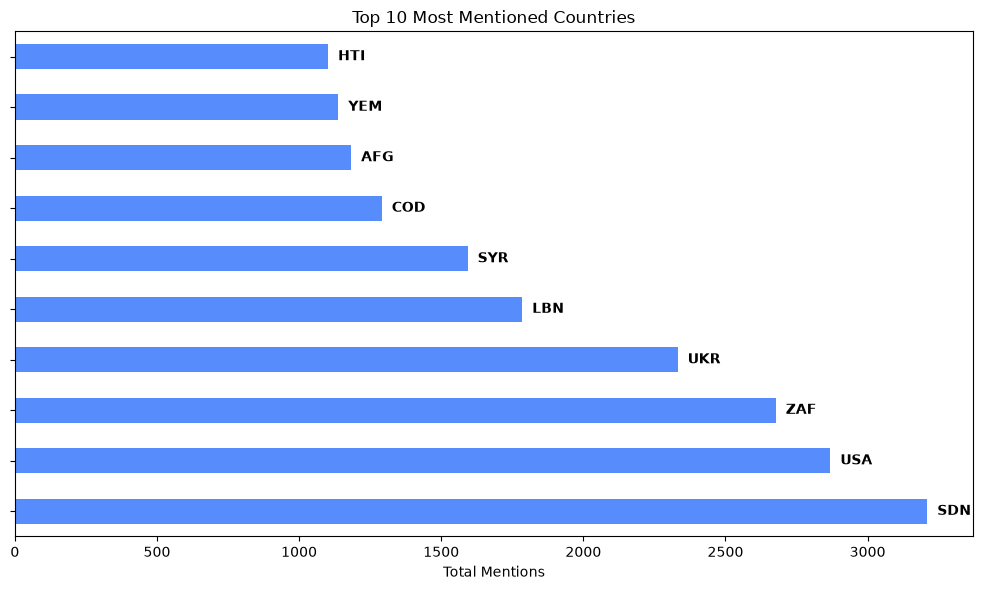

In [24]:
top_10 = heatmap_df.groupby('country_code')['count'].sum().nlargest(10)
logger.info("\nTop 10 countries by mentions:")
print(top_10)

fig, ax = plt.subplots(figsize=(10, 6))
top_10.plot(kind='barh', ax=ax)
ax.set_xlabel('Total Mentions')
ax.set_title('Top 10 Most Mentioned Countries')

# Hide the y-axis
ax.set_yticklabels([])
ax.set_ylabel('')

# Add country codes at the right end of each of the bars
for i, (country, count) in enumerate(top_10.items()):
    ax.text(count, i, f'  {country}', va='center', ha='left', fontweight='bold')

plt.tight_layout()
plt.show()

### Coverage Analysis

In [25]:
# Check top 25 coverage
top_25_countries = heatmap_df.groupby('country_code')['count'].sum().nlargest(25).index
top_25_mentions = heatmap_df[heatmap_df['country_code'].isin(top_25_countries)]['count'].sum()
pct = (top_25_mentions / total_mentions) * 100

logger.info(f"\nTop 25 countries: {top_25_mentions:,.0f} mentions ({pct:.1f}% of total)")
logger.info(f"Remaining {unique_countries - 25} countries: {total_mentions - top_25_mentions:,.0f} mentions ({100-pct:.1f}%)")


2026-10-04 10:13:31.674 | INFO     | __main__:<module>:6 - 
Top 25 countries: 27,148 mentions (72.3% of total)
2026-10-04 10:13:31.675 | INFO     | __main__:<module>:7 - Remaining 171 countries: 10,415 mentions (27.7%)


### Temporal Trends

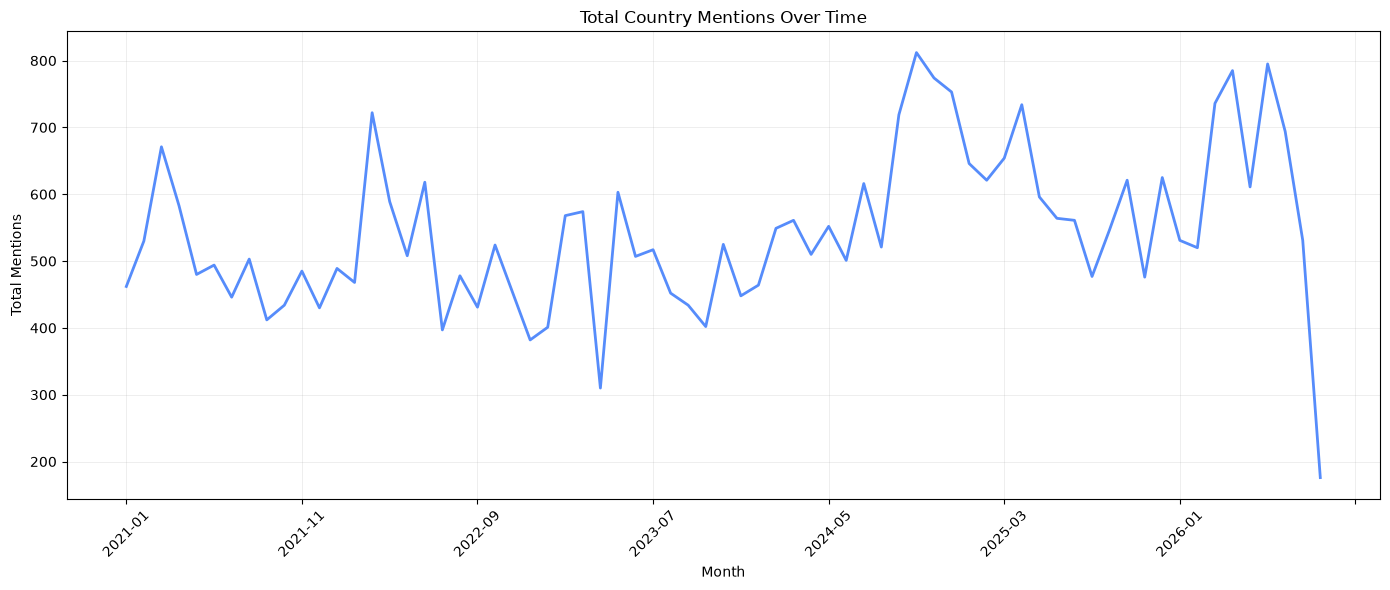

In [18]:
# Total mentions over time
monthly_total = heatmap_df.groupby('month')['count'].sum()

fig, ax = plt.subplots(figsize=(14, 6))
monthly_total.plot(ax=ax, linewidth=2)
ax.set_xlabel('Month')
ax.set_ylabel('Total Mentions')
ax.set_title('Total Country Mentions Over Time')
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Country-Specific Analysis

2026-10-04 10:11:53.672 | INFO     | __main__:<module>:6 - 
USA Analysis:
2026-10-04 10:11:53.673 | INFO     | __main__:<module>:7 - --------------------------------------------------
2026-10-04 10:11:53.675 | INFO     | __main__:<module>:10 - Total mentions: 2,869
2026-10-04 10:11:53.677 | INFO     | __main__:<module>:11 - Number of months active: 69
2026-10-04 10:11:53.679 | INFO     | __main__:<module>:12 - Average mentions per month: 41.6
2026-10-04 10:11:53.679 | INFO     | __main__:<module>:14 - 
Top 5 months for USA:


        month  count
4377  2025-04     82
5333  2026-04     77
4772  2025-09     76
5485  2026-06     76
4844  2025-10     74


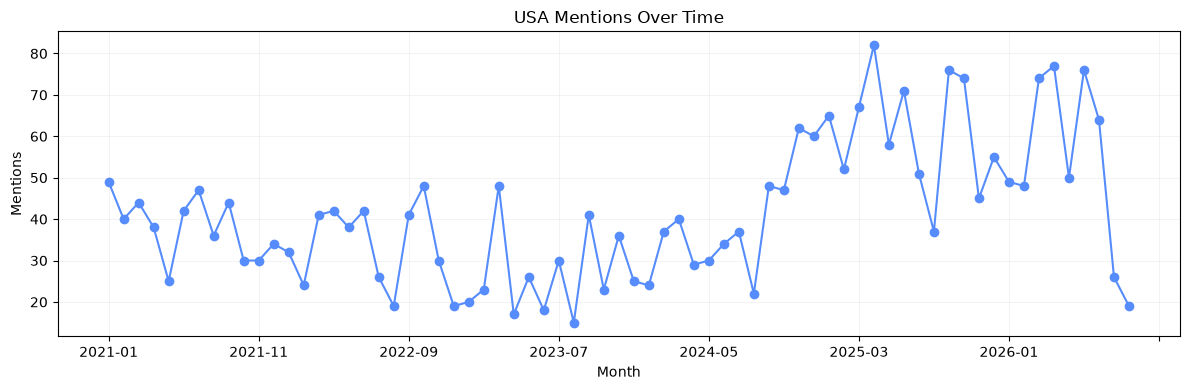

In [23]:
country_code = 'USA'

country_data = heatmap_df[heatmap_df['country_code'] == country_code]

if len(country_data) > 0:
    logger.info(f"\n{country_code} Analysis:")
    logger.info("-" * 50)
    
    total = country_data['count'].sum()
    logger.info(f"Total mentions: {total:,.0f}")
    logger.info(f"Number of months active: {country_data['month'].nunique()}")
    logger.info(f"Average mentions per month: {total / country_data['month'].nunique():.1f}")
    
    logger.info(f"\nTop 5 months for {country_code}:")
    top_months = country_data.nlargest(5, 'count')
    print(top_months[['month', 'count']])

    country_timeline = country_data.set_index('month')['count']
    
    fig, ax = plt.subplots(figsize=(12, 4))
    country_timeline.plot(ax=ax, marker='o')
    ax.set_xlabel('Month')
    ax.set_ylabel('Mentions')
    ax.set_title(f'{country_code} Mentions Over Time')
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
else:
    logger.info(f"No data for country: {country_code}")

## Methodology & Design Decisions

### Data Processing
- **Country matching:** Uses country names and alternatives from Wikipedia, not country codes, to prevent false positives:
  - AND → Andorra (89,223 false matches)
  - PNG → Papua New Guinea, but also "PNG'd" (Persona Non Grata)
  - USA → United States (when used as a common word)
- **Problematic terms removed:** AND, OR, PNG, USA from alternative names
- **Punctuation filtering:** Only alphanumeric alternatives (comma "," was matching PNG)
- **Search method:** Case-insensitive word-boundary regex (`\bterm\b`)
- **Aggregation:** Counts by (month, country_code) pairs

### Visualisation
- **Colour scale:** Log-transformed (log1p) to handle wide range of mention counts
- **Top N:** Display 25 most-mentioned countries (approx. 72% of all mentions)
- **Interactive tools:** Pan, zoom, hover tooltips showing exact counts

### Results Quality
- South Africa (ZAF): 2,677 legitimate mentions (neighboring country, wage comparisons, UN appointments, budget payments)
- Sudan (SDN): Top country with 3,210 mentions
- Haiti (HTI): 10th most mentioned (humanitarian crisis coverage)